# Лабораторная работа №5-6:

Импорт библиотек и подготовка данных

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.manifold import TSNE
import seaborn as sns

# Загрузка данных
df = pd.read_csv('ML-Dataset_cleaned.csv')
features = ['ProductListPrice', 'CustomerCreditLimit', 'Profit_Per_Unit',
            'TotalItemQuantity', 'PerUnitPrice']
X = df[features].copy().dropna()

# Масштабирование
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA для визуализации
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X_scaled)

print(f"Размер данных: {X_scaled.shape}")
print(f"Доля объясненной дисперсии PCA: {pca.explained_variance_ratio_.sum():.2%}")


Размер данных: (400, 5)
Доля объясненной дисперсии PCA: 100.00%


## 1. Иерархическая кластеризация

1.2. Построение дендрограмм для всех комбинаций

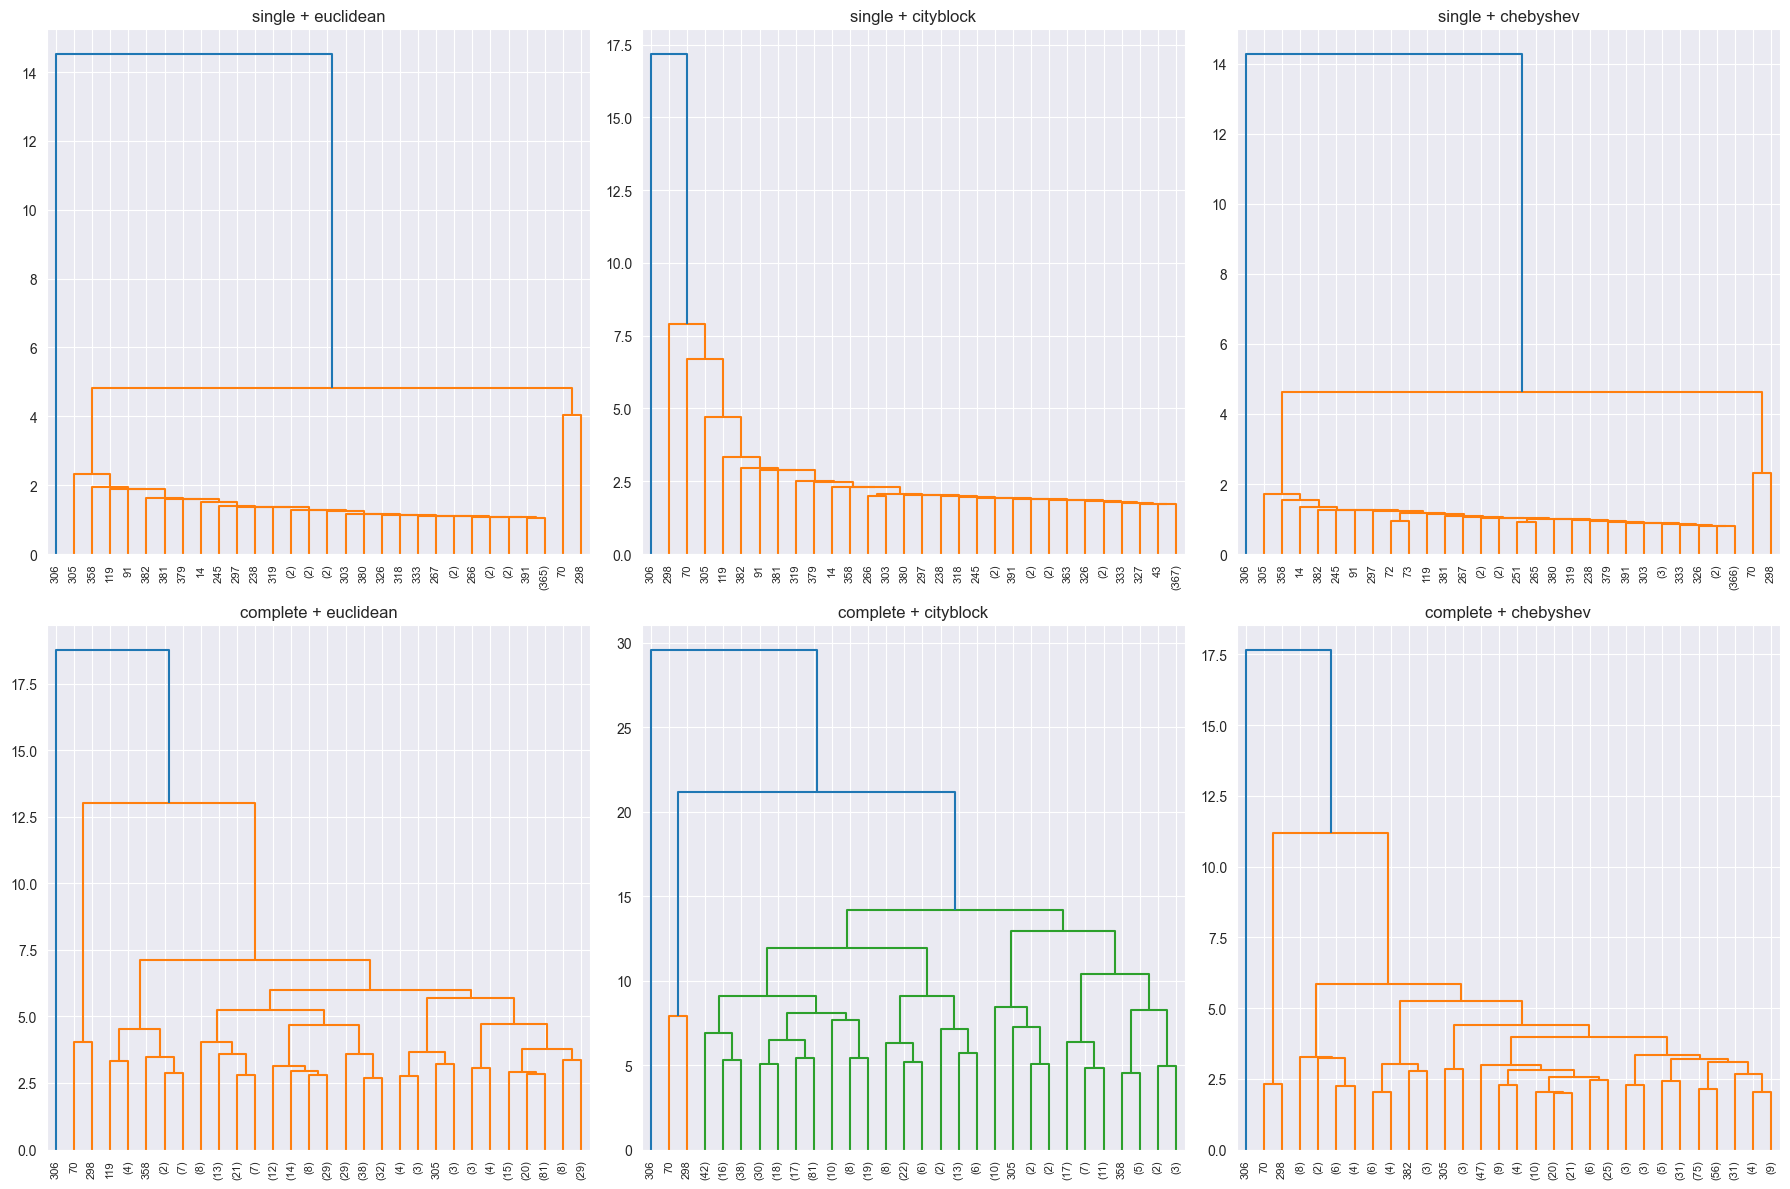

In [64]:
# Параметры для анализа
linkage_methods = ['single', 'complete']
metrics = ['euclidean', 'cityblock', 'chebyshev']

manual_k = {
    'single_euclidean': 2,      #   2
    'single_cityblock': 2,      #   2
    'single_chebyshev': 2,      #   2
    'complete_euclidean': 6,    #   3
    'complete_cityblock': 3,    #   3
    'complete_chebyshev': 6,    #   2
}

USE_MANUAL_K = True

results_hierarchical = {}

for linkage_method in linkage_methods:
    for metric in metrics:
        Z = linkage(X_scaled, method=linkage_method, metric=metric)

        key = f"{linkage_method}_{metric}"

        if USE_MANUAL_K:
            k = manual_k[key]
            model = AgglomerativeClustering(n_clusters=k, linkage=linkage_method, metric=metric)
            labels = model.fit_predict(X_scaled)
            if len(set(labels)) > 1:
                score = silhouette_score(X_scaled, labels, metric=metric)
            else:
                score = -1

            results_hierarchical[key] = {
                'best_k': k,
                'silhouette': score
            }

        else:
            best_score = -1
            best_k = 2
            for k in range(2, 8):
                model = AgglomerativeClustering(n_clusters=k, linkage=linkage_method, metric=metric)
                labels = model.fit_predict(X_scaled)
                if len(set(labels)) > 1:
                    score = silhouette_score(X_scaled, labels, metric=metric)
                    print(f"  k={k}: Silhouette = {score:.4f}")
                    if score > best_score:
                        best_score = score
                        best_k = k

            results_hierarchical[key] = {
                'best_k': best_k,
                'silhouette': best_score
            }
            print(f"\nРекомендуемое k: {best_k} (silhouette = {best_score:.4f})")
# Создание подграфиков 2x3
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

plot_idx = 0

for linkage_method in linkage_methods:
    for metric in metrics:
        # Построение матрицы связей и дендрограммы
        Z = linkage(X_scaled, method=linkage_method, metric=metric)
        dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90,
                   leaf_font_size=8, ax=axes[plot_idx])
        axes[plot_idx].set_title(f'{linkage_method} + {metric}')
        plot_idx += 1

plt.tight_layout()
plt.show()

1.3. Выполнение разбиения на оптимальное k и визуализация

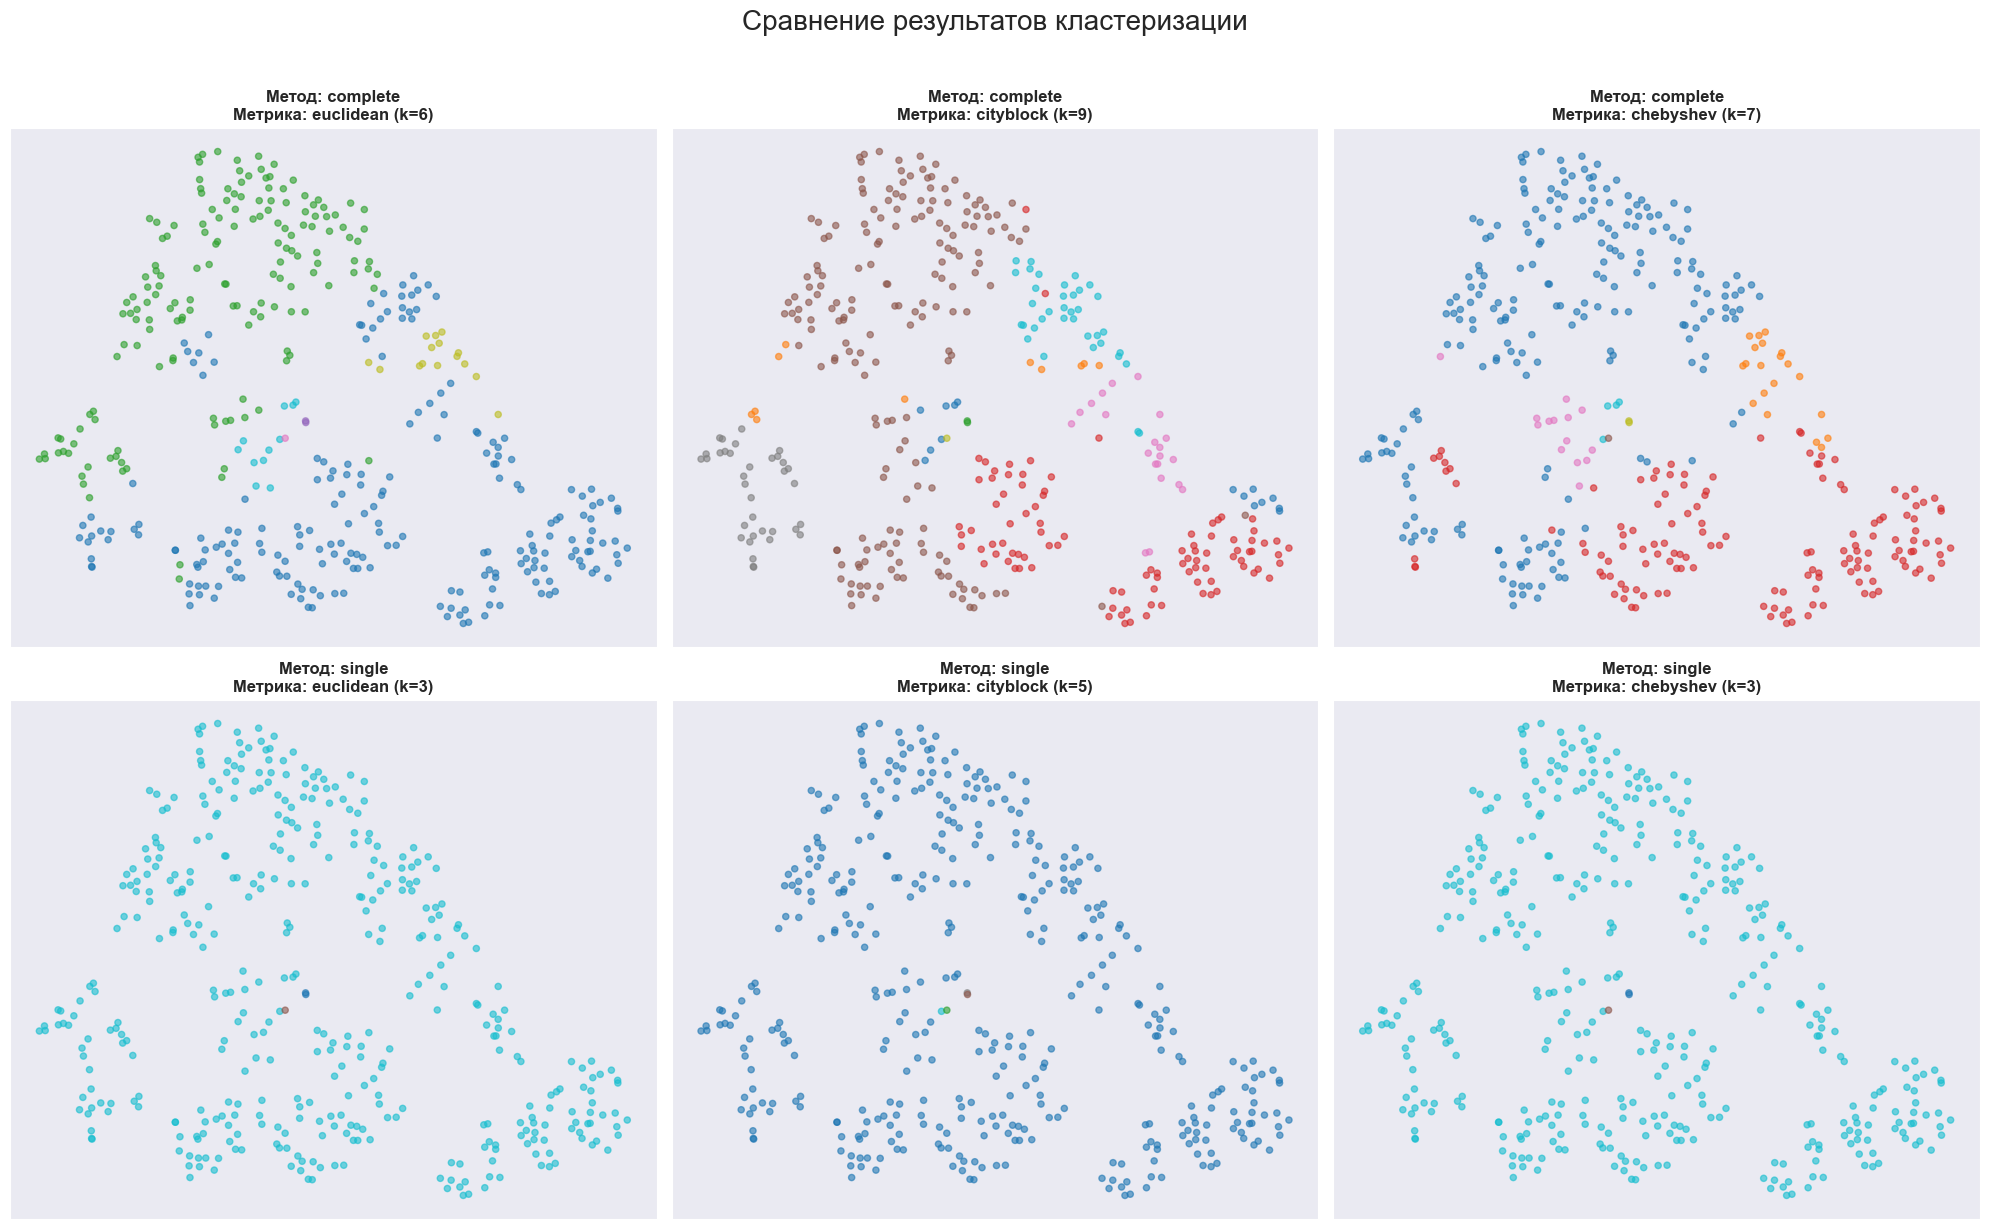

In [65]:
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.manifold import TSNE

# 1. Твои ручные настройки k
manual_k = {
    'single_euclidean': 3,
    'single_cityblock': 5,
    'single_chebyshev': 3,
    'complete_euclidean': 6,
    'complete_cityblock': 9,
    'complete_chebyshev': 7
}

# 2. Вычисляем t-SNE один раз (чтобы сэкономить время и сетка была одинаковой)
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

# 3. Создаем сетку графиков 2x3
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

# Сортируем для красоты: сначала complete, потом single
sorted_configs = sorted(manual_k.keys(), key=lambda x: x.startswith('complete'), reverse=True)

for i, config in enumerate(sorted_configs):
    method, metric = config.split('_')
    k = manual_k[config]

    # Обучаем модель
    model = AgglomerativeClustering(n_clusters=k, linkage=method, metric=metric)
    labels = model.fit_predict(X_scaled)

    # Отрисовка
    ax = axes[i]
    scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1],
                         c=labels,
                         cmap='tab10',
                         s=20,
                         alpha=0.6)

    ax.set_title(f"Метод: {method}\nМетрика: {metric} (k={k})", fontsize=12, fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])

# Настройка общего заголовка и отступов
plt.suptitle("Сравнение результатов кластеризации", fontsize=20, y=1.02)
plt.tight_layout()
plt.show()

1.4. Расчет коэффициента силуэта для каждого разбиения (сводная таблица)

In [66]:
print("\n" + "="*70)
print("Сводная таблица результатов иерархической кластеризации")
print("="*70)
print(f"{'Метод связи':<12} {'Метрика':<12} {'Оптимальное k':<15} {'Silhouette':<12}")
print("-"*70)

for config, data in results_hierarchical.items():
    method, metric = config.split('_')
    print(f"{method:<12} {metric:<12} {data['best_k']:<15} {data['silhouette']:.4f}")


Сводная таблица результатов иерархической кластеризации
Метод связи  Метрика      Оптимальное k   Silhouette  
----------------------------------------------------------------------
single       euclidean    2               0.8529
single       cityblock    2               0.8209
single       chebyshev    2               0.8764
complete     euclidean    6               0.1987
complete     cityblock    3               0.6991
complete     chebyshev    6               0.2162


## 2. Алгоритм k-средних (k-means)


Метрики расстояния: Евклидова (используется по умолчанию), Манхэттенская (для сравнения)

Метод локтя для определения оптимального k


k-means с метрикой: euclidean
Оптимальное k: 6

k-means с метрикой: cityblock
Оптимальное k: 3

k-means с метрикой: chebyshev
Оптимальное k: 2


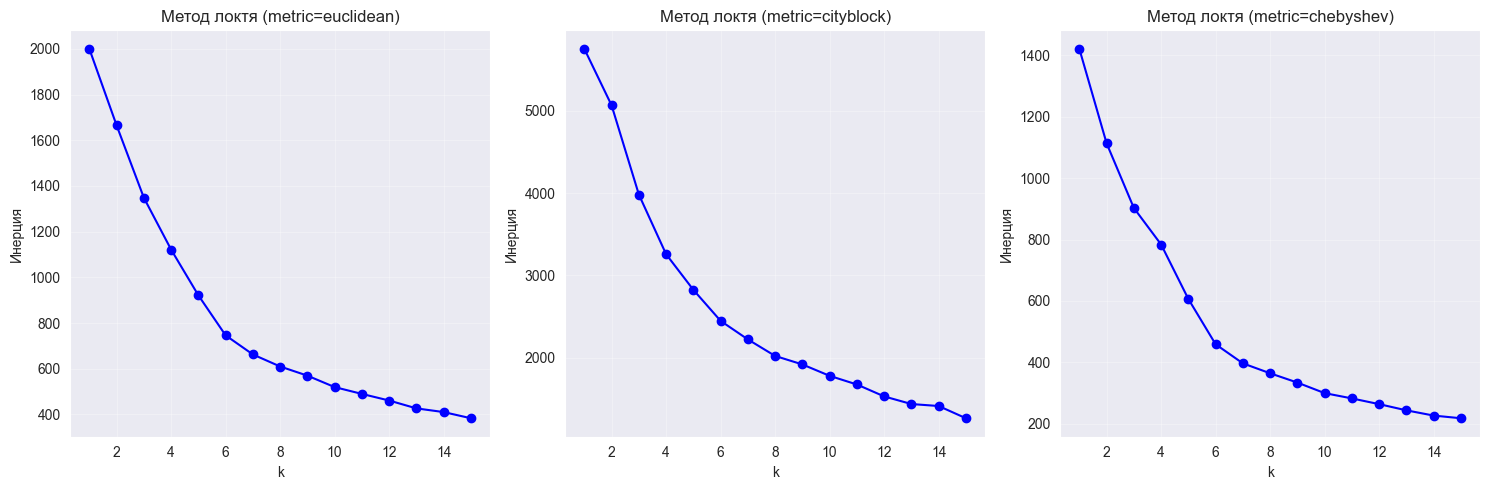

In [67]:
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import pairwise_distances

def elbow_method_kmeans(X_scaled, max_k=15, metric='euclidean'):
    """Вычисление инерции для метода локтя"""
    inertias = []
    k_range = range(1, max_k + 1)

    if metric == 'euclidean':
        for k in k_range:
            kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
            kmeans.fit(X_scaled)
            inertias.append(kmeans.inertia_)
    else:
        for k in k_range:
            kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
            kmeans.fit(X_scaled)
            distances = pairwise_distances(X_scaled, kmeans.cluster_centers_, metric=metric)
            inertia = np.sum(np.min(distances, axis=1) ** 2)
            inertias.append(inertia)

    return k_range, inertias

# Анализ для разных метрик
metrics_kmeans = ['euclidean', 'cityblock', 'chebyshev']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
optimal_k_values = {}

for idx, metric in enumerate(metrics_kmeans):
    print(f"\n{'='*50}")
    print(f"k-means с метрикой: {metric}")
    print('='*50)

    k_range, inertias = elbow_method_kmeans(X_scaled, max_k=15, metric=metric)

    # Построение графика
    axes[idx].plot(k_range, inertias, 'bo-')
    axes[idx].set_title(f'Метод локтя (metric={metric})')
    axes[idx].set_xlabel('k')
    axes[idx].set_ylabel('Инерция')
    axes[idx].grid(True, alpha=0.3)

    # Нахождение точки перегиба (оптимального k)
    diffs = np.diff(inertias)
    diffs2 = np.diff(diffs)
    optimal_k = np.argmax(diffs2) + 2
    optimal_k = max(2, min(optimal_k, 10))

    optimal_k_values[metric] = optimal_k
    print(f"Оптимальное k: {optimal_k}")

plt.tight_layout()
plt.show()

Кластеризация k-means++ с найденным k

In [68]:
# Выполните кластеризацию алгоритмом k-means++ для найденного k с разными метриками

kmeans_results = {}

for metric in metrics_kmeans:
    print(f"\n{'='*50}")
    print(f"k-means++ с метрикой: {metric}")
    optimal_k = optimal_k_values[metric]

    # Кластеризация с найденным k
    if metric == 'euclidean':
        kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_scaled)
    else:
        kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
        kmeans.fit(X_scaled)
        labels = kmeans.labels_

    # Оценка качества
    if len(set(labels)) > 1:
        silhouette = silhouette_score(X_scaled, labels, metric=metric)
        print(f"Коэффициент силуэта: {silhouette:.4f}")
        kmeans_results[metric] = {'k': optimal_k, 'silhouette': silhouette, 'labels': labels}
    else:
        print("Только один кластер!")

# Вывод всех результатов
print(f"\n{'-'*50}")
print("Результаты:")
for metric, result in kmeans_results.items():
    print(f"{metric}: k={result['k']}, silhouette={result['silhouette']:.4f}")


k-means++ с метрикой: euclidean
Коэффициент силуэта: 0.2905

k-means++ с метрикой: cityblock
Коэффициент силуэта: 0.2429

k-means++ с метрикой: chebyshev
Коэффициент силуэта: 0.8266

--------------------------------------------------
Результаты:
euclidean: k=6, silhouette=0.2905
cityblock: k=3, silhouette=0.2429
chebyshev: k=2, silhouette=0.8266


Визуализация лучшего результата k-means

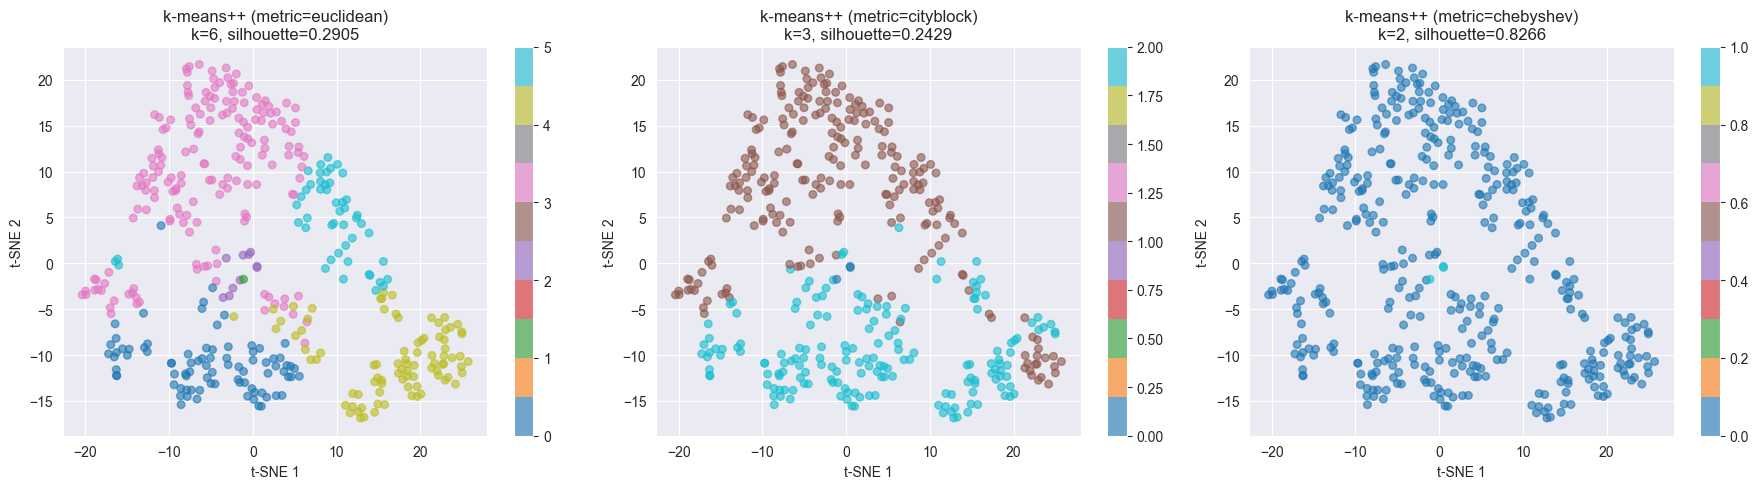

КОЭФ.Т СИЛУЭТА ДЛЯ КАЖДОГО РАЗБИЕНИЯ:
-----------------------------------
Метрика         k     Silhouette
-----------------------------------
euclidean       6     0.2905
cityblock       3     0.2429
chebyshev       2     0.8266


In [69]:


# t-SNE для визуализации
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

# Визуализация результатов для каждой метрики
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (metric, result) in enumerate(kmeans_results.items()):
    # t-SNE визуализация
    scatter = axes[idx].scatter(X_tsne[:, 0], X_tsne[:, 1],
                                c=result['labels'], cmap='tab10', alpha=0.6, s=30)
    axes[idx].set_title(f'k-means++ (metric={metric})\nk={result["k"]}, silhouette={result["silhouette"]:.4f}')
    axes[idx].set_xlabel('t-SNE 1')
    axes[idx].set_ylabel('t-SNE 2')
    plt.colorbar(scatter, ax=axes[idx])

plt.tight_layout()
plt.show()

# Дополнительно: вывод всех силуэтов в таблицу
print("КОЭФ.Т СИЛУЭТА ДЛЯ КАЖДОГО РАЗБИЕНИЯ:")
print("-"*35)
print(f"{'Метрика':<15} {'k':<5} {'Silhouette':<10}")
print("-"*35)
for metric, result in kmeans_results.items():
    print(f"{metric:<15} {result['k']:<5} {result['silhouette']:.4f}")


## 3. Плотностной алгоритм DBSCAN


Метрики расстояния: Евклидова, Манхэттенская

Функция для подбора параметров DBSCAN

In [70]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

def find_optimal_dbscan_params(X_scaled, metric='euclidean'):
    """Поиск оптимальных параметров eps и min_pts для DBSCAN"""
    best_results = []
    min_pts_range = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20]

    for min_pts in min_pts_range:
        if min_pts >= len(X_scaled):
            continue

        # График k-расстояний
        neigh = NearestNeighbors(n_neighbors=min_pts, metric=metric)
        neigh.fit(X_scaled)
        distances, _ = neigh.kneighbors(X_scaled)
        k_distances = np.sort(distances[:, -1])

        # Пробуем разные eps на основе квантилей
        percentiles = [50, 60, 70, 75, 80, 85, 90, 92, 95, 97, 98, 99]

        for p in percentiles:
            eps = np.percentile(k_distances, p)
            if eps < 0.01:
                continue

            dbscan = DBSCAN(eps=eps, min_samples=min_pts, metric=metric)
            labels = dbscan.fit_predict(X_scaled)

            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = list(labels).count(-1)
            noise_ratio = n_noise / len(labels)

            if n_clusters >= 2 and n_clusters <= 15 and noise_ratio <= 0.6:
                mask = labels != -1
                if mask.sum() > 10 and len(set(labels[mask])) >= 2:
                    try:
                        silhouette = silhouette_score(X_scaled[mask], labels[mask], metric=metric)
                        best_results.append({
                            'min_pts': min_pts,
                            'eps': eps,
                            'n_clusters': n_clusters,
                            'n_noise': n_noise,
                            'noise_ratio': noise_ratio,
                            'silhouette': silhouette,
                            'labels': labels,
                            'percentile': p
                        })
                    except Exception:
                        pass

    if best_results:
        best_results.sort(key=lambda x: x['silhouette'], reverse=True)
        return best_results[0]
    return None

Функция построения графика k-расстояний

In [71]:
def plot_k_distance_graph(X_scaled, metric='euclidean', min_pts=4):
    """Построение графика k-расстояний"""
    neigh = NearestNeighbors(n_neighbors=min_pts, metric=metric)
    neigh.fit(X_scaled)
    distances, _ = neigh.kneighbors(X_scaled)
    k_distances = np.sort(distances[:, -1])

    plt.figure(figsize=(10, 5))
    plt.plot(k_distances)
    plt.title(f'График k-расстояний (k={min_pts}, metric={metric})')
    plt.xlabel('Точки, отсортированные по расстоянию')
    plt.ylabel(f'{min_pts}-е расстояние до ближайшего соседа')
    plt.grid(True, alpha=0.3)

    for percentile in [85, 90, 95]:
        eps_val = np.percentile(k_distances, percentile)
        plt.axhline(y=eps_val, color='r', linestyle='--', alpha=0.5,
                   label=f'{percentile}% = {eps_val:.3f}')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return k_distances

Подбор параметров для каждой метрики

ПОДБОР ПАРАМЕТРОВ DBSCAN

DBSCAN с метрикой: euclidean


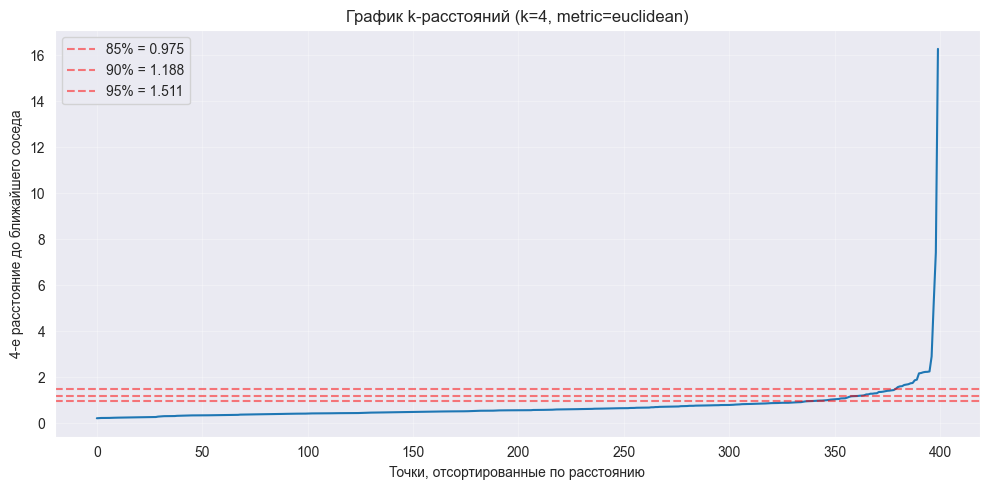

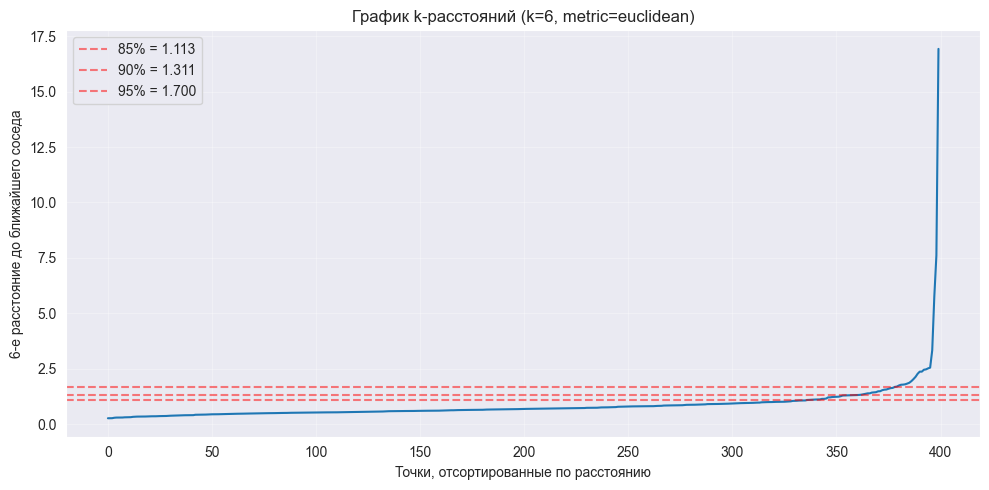

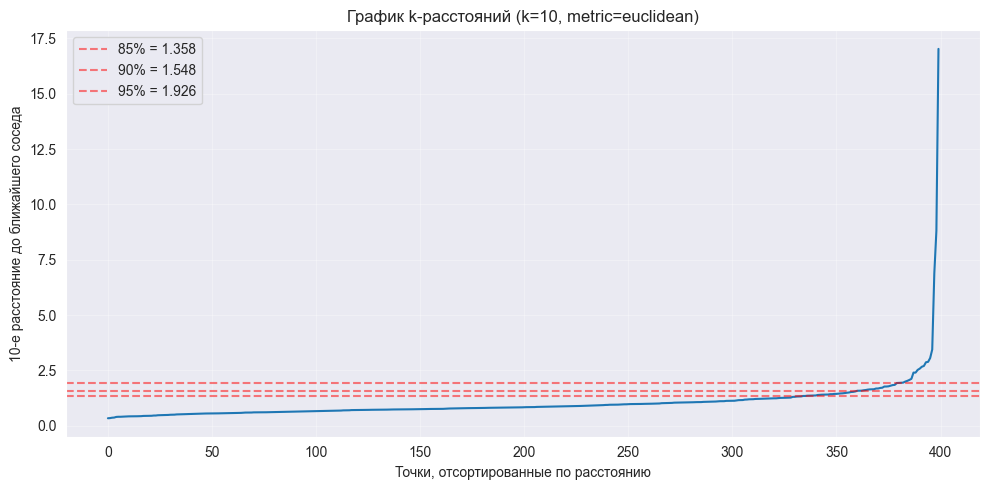


✓ Найдены оптимальные параметры:
  min_pts = 4
  eps = 0.9752 (перцентиль: 85%)
  Количество кластеров: 3
  Количество шумовых точек: 44 (11.0%)
  Коэффициент силуэта (без шума): 0.2480

DBSCAN с метрикой: cityblock


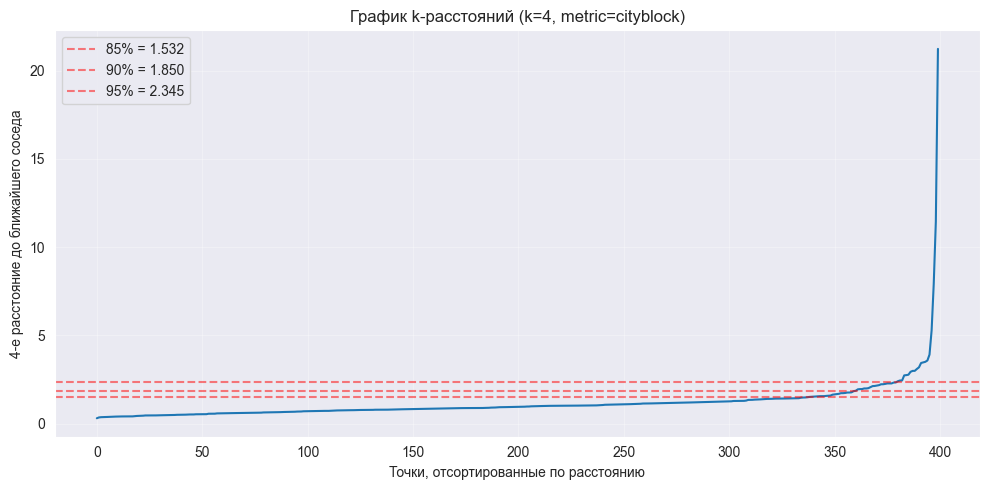

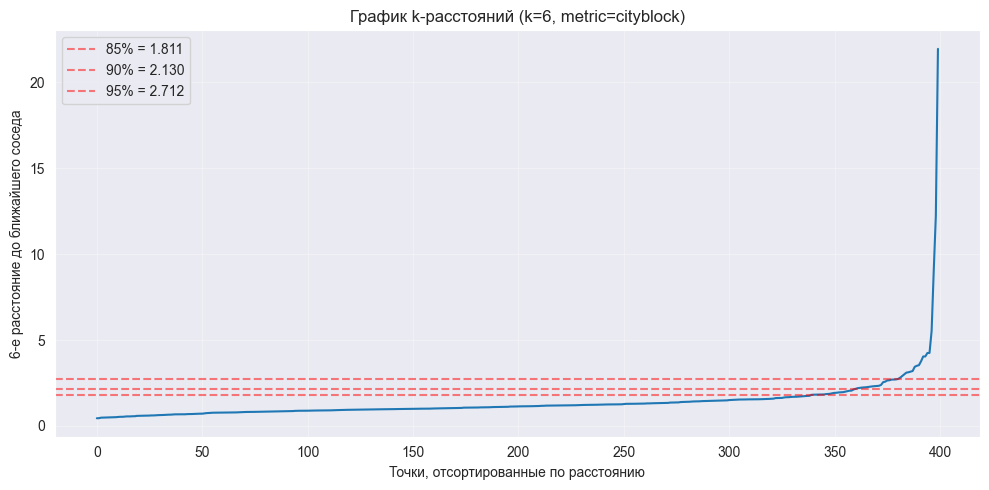

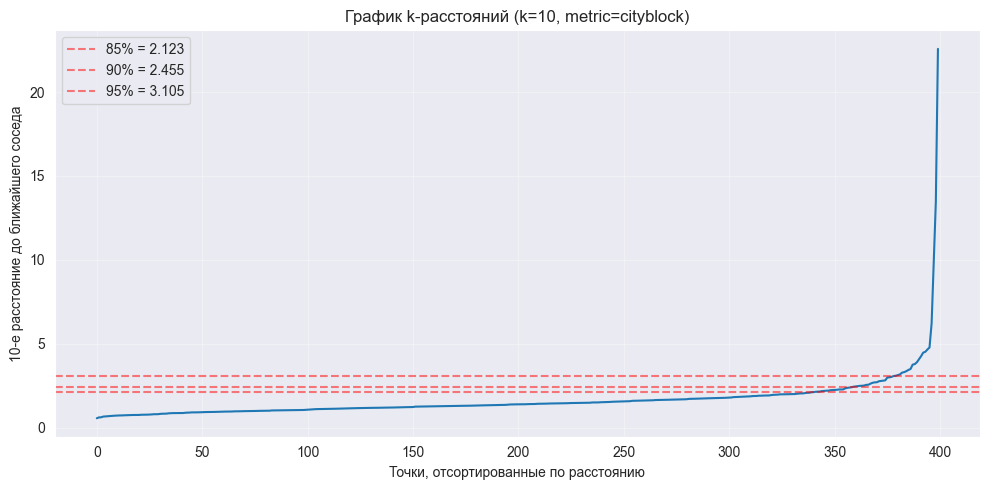


✓ Найдены оптимальные параметры:
  min_pts = 4
  eps = 1.4115 (перцентиль: 80%)
  Количество кластеров: 2
  Количество шумовых точек: 52 (13.0%)
  Коэффициент силуэта (без шума): 0.3019


In [72]:
metrics_dbscan = ['euclidean', 'cityblock']
dbscan_results = {}

print("="*60)
print("ПОДБОР ПАРАМЕТРОВ DBSCAN")
print("="*60)

for metric in metrics_dbscan:
    print(f"\n{'='*50}")
    print(f"DBSCAN с метрикой: {metric}")
    print('='*50)

    # Графики k-расстояний для разных k
    for k in [4, 6, 10]:
        plot_k_distance_graph(X_scaled, metric=metric, min_pts=k)

    # Поиск оптимальных параметров
    best = find_optimal_dbscan_params(X_scaled, metric=metric)

    if best:
        print(f"\n✓ Найдены оптимальные параметры:")
        print(f"  min_pts = {best['min_pts']}")
        print(f"  eps = {best['eps']:.4f} (перцентиль: {best['percentile']}%)")
        print(f"  Количество кластеров: {best['n_clusters']}")
        print(f"  Количество шумовых точек: {best['n_noise']} ({best['noise_ratio']:.1%})")
        print(f"  Коэффициент силуэта (без шума): {best['silhouette']:.4f}")
        dbscan_results[metric] = best
    else:
        print(f"\n✗ Не удалось найти подходящие параметры для метрики {metric}")

Визуализация результатов DBSCAN

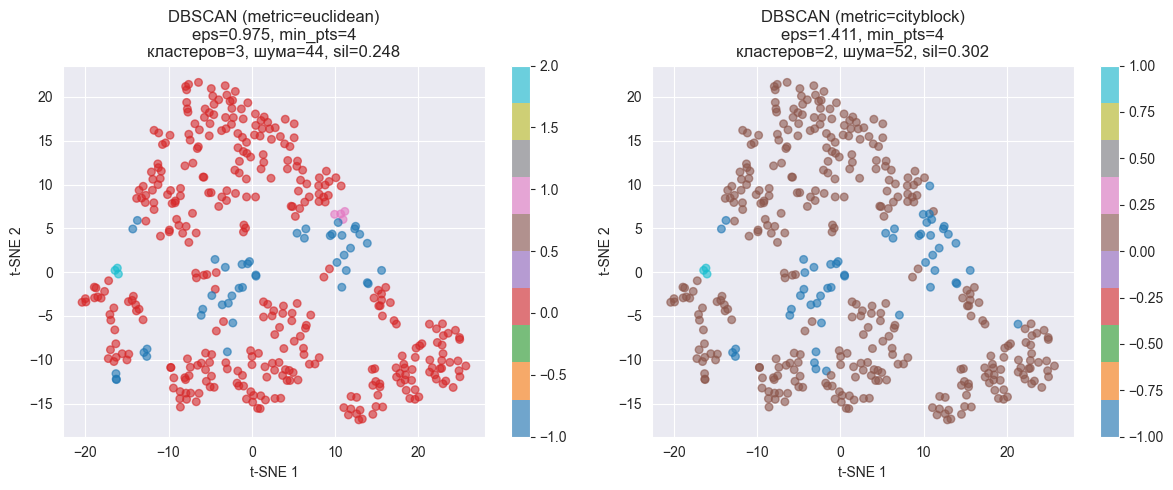

In [77]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

# Визуализация результатов DBSCAN для каждой метрики
if dbscan_results:
    fig, axes = plt.subplots(1, len(dbscan_results), figsize=(6*len(dbscan_results), 5))
    if len(dbscan_results) == 1:
        axes = [axes]

    for idx, (metric, result) in enumerate(dbscan_results.items()):
        labels = result['labels']
        n_clusters = result['n_clusters']
        n_noise = result['n_noise']
        # Шумовые точки (метка -1) выделяем другим цветом и маркером
        scatter = axes[idx].scatter(X_tsne[:, 0], X_tsne[:, 1],
                                    c=labels, cmap='tab10', alpha=0.6, s=30)
        axes[idx].set_title(f'DBSCAN (metric={metric})\neps={result["eps"]:.3f}, min_pts={result["min_pts"]}\n'
                           f'кластеров={n_clusters}, шума={n_noise}, sil={result["silhouette"]:.3f}')
        axes[idx].set_xlabel('t-SNE 1')
        axes[idx].set_ylabel('t-SNE 2')
        plt.colorbar(scatter, ax=axes[idx])
    plt.tight_layout()
    plt.show()



Рассчитайте коэффициент силуэта

In [74]:
for metric, result in dbscan_results.items():
    labels = result['labels']

    # Исключаем шумовые точки (метка -1)
    mask = labels != -1
    X_filtered = X_scaled[mask]
    labels_filtered = labels[mask]

    n_clusters = len(set(labels_filtered))
    n_noise = (~mask).sum()

    print(f"\n{metric}:")
    print(f"  Всего точек: {len(labels)}")
    print(f"  Точек в кластерах: {len(X_filtered)}")
    print(f"  Количество кластеров: {n_clusters}")



euclidean:
  Всего точек: 400
  Точек в кластерах: 356
  Количество кластеров: 3

cityblock:
  Всего точек: 400
  Точек в кластерах: 348
  Количество кластеров: 2


## 4. Сравнение результатов

In [75]:
import pandas as pd

# Сбор данных для сводной таблицы
comparison_data = []

print("\n" + "-"*80)
print("Результаты иерархической кластеризации")
for config, result in results_hierarchical.items():
    linkage_method, metric = config.split('_')
    comparison_data.append({
        'Алгоритм': 'Иерархическая',
        'Метрика': metric,
        'Метод связи': linkage_method,
        'k (кластеры)': result['best_k'],
        'Шум (DBSCAN)': '-',
        'Silhouette': result['silhouette'],
        #'Визуальная оценка': 'Хорошо разделимые кластеры' if result['silhouette'] > 0.5 else 'Среднее разделение'
    })
    print(f"Иерархическая: {linkage_method}+{metric} → k={result['best_k']}, sil={result['silhouette']:.4f}")

# 2. K-means++ (kmeans_results)
print("\n" + "-"*80)
print("Результаты K-MEANS++")
for metric, result in kmeans_results.items():
    comparison_data.append({
        'Алгоритм': 'K-means++',
        'Метрика': metric,
        'Метод связи': '-',
        'k (кластеры)': result['k'],
        'Шум (DBSCAN)': '-',
        'Silhouette': result['silhouette'],
        #'Визуальная оценка': 'Хорошо разделимые кластеры' if result['silhouette'] > 0.5 else 'Среднее разделение'
    })
    print(f"K-means++: {metric} → k={result['k']}, sil={result['silhouette']:.4f}")

# 3. DBSCAN (dbscan_results)
print("\n" + "-"*80)
print("Результаты DBSCAN")

for metric, result in dbscan_results.items():
    comparison_data.append({
        'Алгоритм': 'DBSCAN',
        'Метрика': metric,
        'Метод связи': '-',
        'k (кластеры)': f"{result['n_clusters']} (+{result['n_noise']} шума)",
        'Шум (DBSCAN)': result['n_noise'],
        'Silhouette': result['silhouette'],
        #'Визуальная оценка': f" шум {result['noise_ratio']:.1%}"
    })
    print(f"DBSCAN: {metric} → кластеров={result['n_clusters']}, шума={result['n_noise']}, sil={result['silhouette']:.4f}")

# Создание сводной таблицы
df_comparison = pd.DataFrame(comparison_data)

# Сортировка по силуэту (от лучшего к худшему)
df_comparison = df_comparison.sort_values('Silhouette', ascending=False)

# Вывод таблицы
print("\n" + "-"*80)
print("СВОДНАЯ ТАБЛИЦА СРАВНЕНИЯ АЛГОРИТМОВ")
print(df_comparison.to_string(index=False))



--------------------------------------------------------------------------------
Результаты иерархической кластеризации
Иерархическая: single+euclidean → k=2, sil=0.8529
Иерархическая: single+cityblock → k=2, sil=0.8209
Иерархическая: single+chebyshev → k=2, sil=0.8764
Иерархическая: complete+euclidean → k=6, sil=0.1987
Иерархическая: complete+cityblock → k=3, sil=0.6991
Иерархическая: complete+chebyshev → k=6, sil=0.2162

--------------------------------------------------------------------------------
Результаты K-MEANS++
K-means++: euclidean → k=6, sil=0.2905
K-means++: cityblock → k=3, sil=0.2429
K-means++: chebyshev → k=2, sil=0.8266

--------------------------------------------------------------------------------
Результаты DBSCAN
DBSCAN: euclidean → кластеров=3, шума=44, sil=0.2480
DBSCAN: cityblock → кластеров=2, шума=52, sil=0.3019

--------------------------------------------------------------------------------
СВОДНАЯ ТАБЛИЦА СРАВНЕНИЯ АЛГОРИТМОВ
     Алгоритм   Метрика Мето